# 6. Analysis

Module importing

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")

Library importing

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.dummy import DummyRegressor
from src.config import FIGURES_DIR, MODELS_DIR, V_GRID, ROOT
from src.data import load_cache, clean_capacity
from src.splits import SPLITS
from src.features import build_feature_table, VARIANCE_FEATURES, DISCHARGE_FEATURES, FULL_FEATURES
from src.models import make_elastic_net, make_lgbm, conformal_intervals, coverage
from src.evaluate import score, results_table, parity_plot

cells = load_cache()
tables = {name: build_feature_table(cells, ids) for name, ids in SPLITS.items()}
y_train = tables["train"]["cycle_life"]
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

Cross-validation table for all the classical models

In [3]:
_, leaves, n_est, lr = joblib.load(MODELS_DIR / "lgbm_best_params.joblib")

def make_lgbm_tuned():
    m = make_lgbm()
    m.regressor.set_params(num_leaves=leaves, n_estimators=n_est, learning_rate=lr)
    return m

CANDIDATES = {
    "mean baseline":           (lambda: DummyRegressor(strategy="mean"), FULL_FEATURES),
    "elastic net (variance)":  (make_elastic_net, VARIANCE_FEATURES),
    "elastic net (discharge)": (make_elastic_net, DISCHARGE_FEATURES),
    "elastic net (full)":      (make_elastic_net, FULL_FEATURES),
    "LightGBM (full, tuned)":  (make_lgbm_tuned, FULL_FEATURES),
}
cv_rows = []
for name, (factory, feats) in CANDIDATES.items():
    oof = cross_val_predict(factory(), tables["train"][feats], y_train, cv=LeaveOneOut())
    cv_rows.append({"model": name, **score(y_train, oof)})
cv_table = pd.DataFrame(cv_rows).set_index("model").sort_values("RMSE (cycles)")
cv_table

,RMSE (cycles),MAPE (%)
model,,
elastic net (discharge),110.9,13.1
elastic net (full),111.5,12.1
elastic net (variance),126.8,16.6
"LightGBM (full, tuned)",228.5,14.0
mean baseline,330.9,34.3


Best model

In [4]:
FINAL_NAME = "elastic net (discharge)"
FINAL_FACTORY, FINAL_FEATURES = CANDIDATES[FINAL_NAME]

Load results

In [5]:
results = {**joblib.load(MODELS_DIR / "results_classical.joblib"),
           **joblib.load(MODELS_DIR / "results_cnn.joblib")}
test_table = results_table(results)
test_table

RMSE (cycles)                           MAPE (%)  \
split                     primary_test secondary_test  train primary_test   
model                                                                       
1D CNN (5-seed ensemble)         317.6          372.9  238.6         14.8   
LightGBM (full, tuned)           215.9          350.4  133.8         13.2   
elastic net (discharge)          221.2          143.9   78.5         13.6   
elastic net (full)               136.0          261.5   80.1         10.3   
elastic net (variance)           136.6          211.4  121.7         15.4   
mean baseline                    388.8          469.9  322.8         31.9   

                                               
split                    secondary_test train  
model                                          
1D CNN (5-seed ensemble)           21.0  13.3  
LightGBM (full, tuned)             17.1   5.0  
elastic net (discharge)            10.4  10.4  
elastic net (full)                 15.3   9.0  
elastic net (variance)             11.9  16.1  
mean baseline                      31.2  33.5

Published reference rows

In [6]:
reference = pd.DataFrame(
    {("RMSE (cycles)", "primary_test"):   [398, 136, 334],
     ("RMSE (cycles)", "secondary_test"): [510, 211, 799]},
    index=["[BatteryML] mean baseline", "[BatteryML] variance model", "[BatteryML] XGBoost"],
)
final_table = pd.concat([test_table, reference])
final_table.to_csv(ROOT / "reports" / "results_table.csv")
final_table

RMSE (cycles)                           MAPE (%)  \
                            primary_test secondary_test  train primary_test   
1D CNN (5-seed ensemble)           317.6          372.9  238.6         14.8   
LightGBM (full, tuned)             215.9          350.4  133.8         13.2   
elastic net (discharge)            221.2          143.9   78.5         13.6   
elastic net (full)                 136.0          261.5   80.1         10.3   
elastic net (variance)             136.6          211.4  121.7         15.4   
mean baseline                      388.8          469.9  322.8         31.9   
[BatteryML] mean baseline          398.0          510.0    NaN          NaN   
[BatteryML] variance model         136.0          211.0    NaN          NaN   
[BatteryML] XGBoost                334.0          799.0    NaN          NaN   

                                                 
                           secondary_test train  
1D CNN (5-seed ensemble)             21.0  13.3  
LightGBM (full, tuned)               17.1   5.0  
elastic net (discharge)              10.4  10.4  
elastic net (full)                   15.3   9.0  
elastic net (variance)               11.9  16.1  
mean baseline                        31.2  33.5  
[BatteryML] mean baseline             NaN   NaN  
[BatteryML] variance model            NaN   NaN  
[BatteryML] XGBoost                   NaN   NaN

CNN

In [7]:
spread = joblib.load(MODELS_DIR / "cnn_seed_spread.joblib")
for s, v in spread.items():
    print(f"CNN single seeds, {s}: {np.mean(v):.0f} ± {np.std(v):.0f} RMSE (min {min(v):.0f}, max {max(v):.0f})")

CNN single seeds, primary_test: 322 ± 37 RMSE (min 291, max 394)
CNN single seeds, secondary_test: 378 ± 70 RMSE (min 300, max 508)


Markdown 

In [8]:
print(final_table.round(1).to_markdown())

|                            |   ('RMSE (cycles)', 'primary_test') |   ('RMSE (cycles)', 'secondary_test') |   ('RMSE (cycles)', 'train') |   ('MAPE (%)', 'primary_test') |   ('MAPE (%)', 'secondary_test') |   ('MAPE (%)', 'train') |
|:---------------------------|------------------------------------:|--------------------------------------:|-----------------------------:|-------------------------------:|---------------------------------:|------------------------:|
| 1D CNN (5-seed ensemble)   |                               317.6 |                                 372.9 |                        238.6 |                           14.8 |                             21   |                    13.3 |
| LightGBM (full, tuned)     |                               215.9 |                                 350.4 |                        133.8 |                           13.2 |                             17.1 |                     5   |
| elastic net (discharge)    |                               221

How far off your predictions are

split        primary_test  secondary_test
cycles used                              
20                   24.0            41.9
40                   15.3            20.4
60                  137.8            14.0
80                   16.9            12.3
100                  13.6            10.4


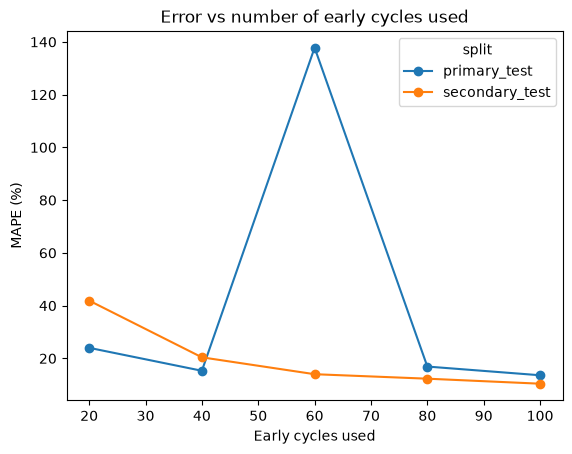

In [9]:
rows = []
for late in [20, 40, 60, 80, 100]:
    tb = {s: build_feature_table(cells, ids, late=late) for s, ids in SPLITS.items()}
    m = FINAL_FACTORY().fit(tb["train"][FINAL_FEATURES], tb["train"]["cycle_life"])
    for s in ["primary_test", "secondary_test"]:
        rows.append({"cycles used": late, "split": s,
                     **score(tb[s]["cycle_life"], m.predict(tb[s][FINAL_FEATURES]))})
early = pd.DataFrame(rows)
curve = early.pivot(index="cycles used", columns="split", values="MAPE (%)")
print(curve.round(1))

ax = curve.plot(marker="o", ylabel="MAPE (%)", xlabel="Early cycles used",
                title="Error vs number of early cycles used")
ax.figure.savefig(FIGURES_DIR / "early_cycles.png", dpi=150, bbox_inches="tight")

Error for every test cell

In [10]:
final = FINAL_FACTORY().fit(tables["train"][FINAL_FEATURES], y_train)
err = pd.concat([tables[s].assign(split=s) for s in ["primary_test", "secondary_test"]])
err["pred"] = final.predict(err[FINAL_FEATURES])
err["pct_error"] = 100 * (err["pred"] - err["cycle_life"]) / err["cycle_life"]
err["batch"] = err.index.str[:2]

print(err.sort_values("pct_error", key=abs, ascending=False)[["split", "cycle_life", "pred", "pct_error"]].head(8))
print(err.groupby("batch")["pct_error"].agg(mean_error="mean",
                                             mean_abs_error=lambda s: s.abs().mean(),
                                             n="count").round(1))

                  split  cycle_life         pred  pct_error
cell_id                                                    
b1c41      primary_test      1049.0    84.785620 -91.917481
b2c24      primary_test       494.0   236.747752 -52.075354
b1c0       primary_test      1850.0  2777.551739  50.137932
b2c28      primary_test       509.0   684.379026  34.455604
b2c18      primary_test       486.0   642.381762  32.177317
b2c20      primary_test       501.0   356.647903 -28.812794
b3c38    secondary_test      1933.0  1396.367853 -27.761622
b3c40    secondary_test       794.0  1003.276186  26.357202
       mean_error  mean_abs_error   n
batch                                
b1           -4.3            11.8  21
b2            0.1            15.3  21
b3            4.4            10.4  40


Check whether error depends on lifetime

Spearman(error, life) = 0.03


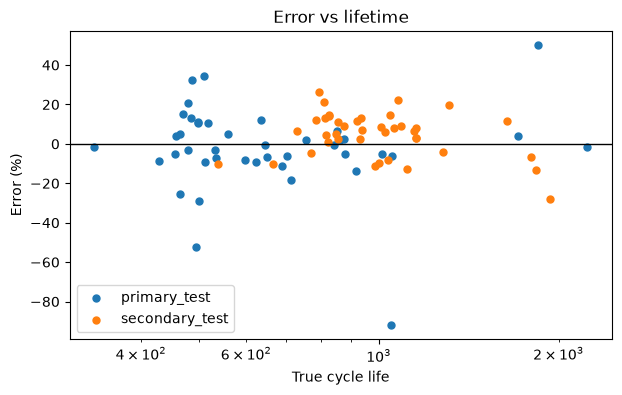

In [11]:
from scipy.stats import spearmanr
fig, ax = plt.subplots(figsize=(7, 4))
for s, g in err.groupby("split"):
    ax.scatter(g["cycle_life"], g["pct_error"], label=s, s=25)
ax.axhline(0, c="k", lw=1); ax.set_xscale("log")
ax.set(xlabel="True cycle life", ylabel="Error (%)", title="Error vs lifetime"); ax.legend()
fig.savefig(FIGURES_DIR / "error_vs_life.png", dpi=150, bbox_inches="tight")
print("Spearman(error, life) =", round(spearmanr(err["cycle_life"], err["pct_error"])[0], 2))

Compare each of the 5 worst cells with a well-predicted cell of similar life

b1c41 protocol: [{'rate_in_C': 8.0, 'current_in_A': None, 'voltage_in_V': None, 'power_in_W': None, 'start_voltage_in_V': None, 'start_soc': 0.0, 'end_voltage_in_V': None, 'end_soc': 15.0}, {'rate_in_C': 3.6, 'current_in_A': None, 'voltage_in_V': None, 'power_in_W': None, 'start_voltage_in_V': None, 'start_soc': 15.0, 'end_voltage_in_V': None, 'end_soc': 1.0}] | twin b3c19 : [{'rate_in_C': 5.6, 'current_in_A': None, 'voltage_in_V': None, 'power_in_W': None, 'start_voltage_in_V': None, 'start_soc': 0.0, 'end_voltage_in_V': None, 'end_soc': 36.0}, {'rate_in_C': 4.3, 'current_in_A': None, 'voltage_in_V': None, 'power_in_W': None, 'start_voltage_in_V': None, 'start_soc': 36.0, 'end_voltage_in_V': None, 'end_soc': 1.0}]
b2c24 protocol: [{'rate_in_C': 4.8, 'current_in_A': None, 'voltage_in_V': None, 'power_in_W': None, 'start_voltage_in_V': None, 'start_soc': 0.0, 'end_voltage_in_V': None, 'end_soc': 80.0}, {'rate_in_C': 4.8, 'current_in_A': None, 'voltage_in_V': None, 'power_in_W': None, 's

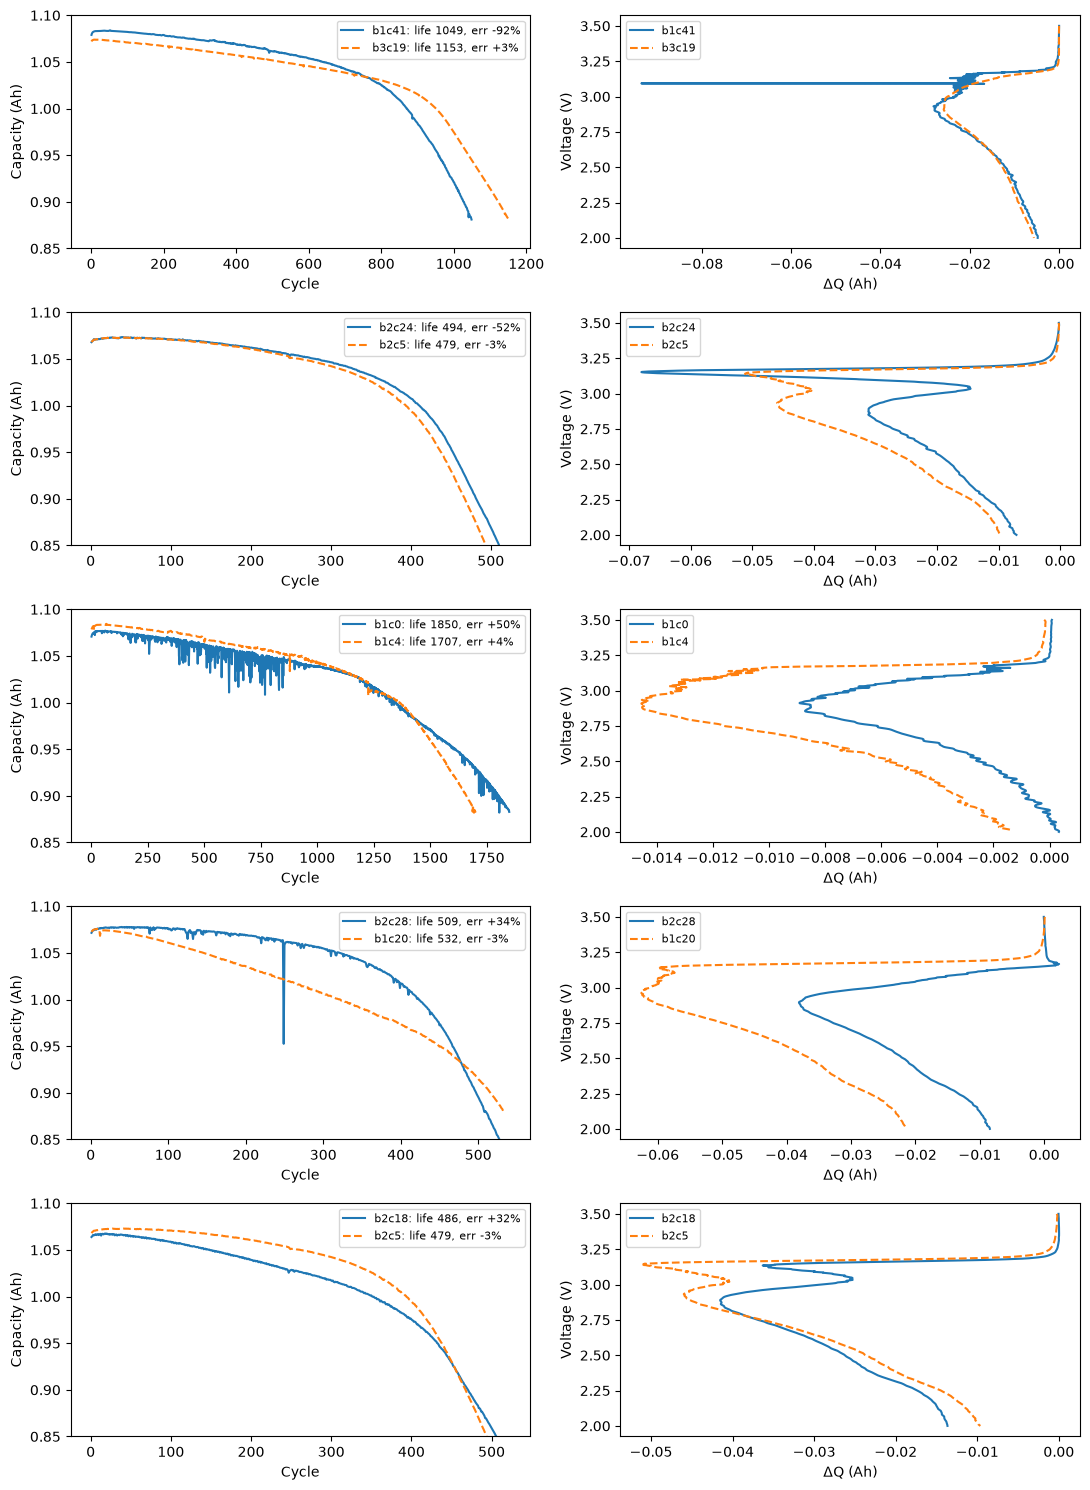

In [12]:
worst = err["pct_error"].abs().sort_values(ascending=False).index[:5]
good = err[err["pct_error"].abs() < 5]      # raise to 10 if this comes back empty
fig, axes = plt.subplots(5, 2, figsize=(11, 15))
for row, cid in zip(axes, worst):
    twin = (good["cycle_life"] - err.loc[cid, "cycle_life"]).abs().idxmin()
    for c, ls in [(cid, "-"), (twin, "--")]:
        qd = clean_capacity(cells[c]["qd"])
        lab = f"{c}: life {err.loc[c,'cycle_life']:.0f}, err {err.loc[c,'pct_error']:+.0f}%"
        row[0].plot(np.arange(1, len(qd) + 1), qd, ls, label=lab)
        row[1].plot(cells[c]["qdlin"][99] - cells[c]["qdlin"][9], V_GRID, ls, label=c)
    row[0].set(xlabel="Cycle", ylabel="Capacity (Ah)", ylim=(0.85, 1.1)); row[0].legend(fontsize=8)
    row[1].set(xlabel="ΔQ (Ah)", ylabel="Voltage (V)"); row[1].legend(fontsize=8)
    print(cid, "protocol:", cells[cid]["charge_protocol"], "| twin", twin, ":", cells[twin]["charge_protocol"])
fig.tight_layout(); fig.savefig(FIGURES_DIR / "worst_cells.png", dpi=150)